# 08 – Children-only audience classifier (separate experiment; notebooks 06 and 07 are unchanged)

**Target.** The **intended audience** of a book: is it written and published mainly for **children up to about age 12**? Teen/young-adult books and adult books are the negatives. This is *not* a guarantee of age suitability and *not* the catalogue's `juvenile` subject marker (which also covers teen books and is applied inconsistently — notebooks 06/07 predict that marker).

**Labels are provisional.** They were assigned by an AI labeller (Claude) under the written rules in `docs/CHILDREN_LABEL_RULES.md`, reading only title, author, year, pages and the start of the description, blind to the catalogue marker and to any model output. They are not human-verified; an 80-book manual review sheet (including all uncertain cases) is in `report/ml/children/review/`. Results below are therefore *agreement with provisional labels*.

**Design (fixed before any fresh-test evaluation).**
* **Training labels:** 797 usable books = the 392 pilot labels + 158 exploratory-check labels + 247 new random labels, all grouped by `ol_group` into 5 grouped CV folds. The 158 books were examined while the pilot was developed, so they are used **only as training data**.
* **Fresh test set:** 291 usable books (300 sampled, 9 uncertain excluded) drawn at random from the phase-2 test side, in work groups disjoint from every training label. Evaluated **once**, after the model choice is saved.
* **A – metadata only** (title words, creators, pages, year, title length, and a juvenile-tag score computed *without* descriptions). **B – the same plus the real description text** (description words and a description-based juvenile-tag score). Both variants use the same books, folds and tuning grid.
* **Out-of-fold scores.** A juvenile-tag score used as a feature is produced out of fold with the saved grouped phase-2 folds for pool books, and by the full-pool model for books of the phase-2 test side (which that model never trained on). Variant A never receives a score built from descriptions.
* Models are chosen by training cross-validation on the **F1 of the children class** (declared in advance); the default 0.5 threshold is kept.

In [1]:
import json, time, warnings, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import phase2_experiment as p2, children_audience as ca
OUT = ca.OUT; OUT.mkdir(parents=True, exist_ok=True); FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 70, "display.max_rows", 120)
env = {**p2.environment(), "labels_sha256": ca.sha256_file(ca.LABELS_FILE), "label_rules": "docs/CHILDREN_LABEL_RULES.md", "criterion": "CV F1 of the children class"}
(OUT / "environment_children.json").write_text(json.dumps(env, indent=2), encoding="utf-8")
print({k: env[k] for k in ("python", "scikit-learn", "numpy", "pandas", "seed", "labels_sha256")})

{'python': '3.13.2', 'scikit-learn': '1.6.1', 'numpy': '2.2.3', 'pandas': '2.2.3', 'seed': 2026, 'labels_sha256': '91f95f65488a6415d216473cf26f2f87e9ce17846d2b7f088b189a022ae745e6'}


## 1. Labels: counts, and the 392 versus 394 question

In [2]:
L = ca.load_labels()
inv = ca.inventory(L); display(inv)
inv.to_csv(OUT / "label_inventory.csv")
p = inv.loc["train_pilot400"]
print(f"Pilot sample: {int(p.total)} books = {int(p.C)} children + {int(p.Y)} teen + {int(p.A)} adult ({int(p['usable (C+Y+A)'])} usable) + {int(p['?'])} unsure (excluded).")
print("The earlier message said '394'; that was an arithmetic slip (it assumed 6 unsure books before counting). The code always used the 392 usable rows.")
tot_tr = inv.loc[list(ca.TRAIN_ROLES), "usable (C+Y+A)"].sum(); print("Usable training labels:", int(tot_tr), "| usable fresh-test labels:", int(inv.loc['fresh_test', 'usable (C+Y+A)']))

label,C,Y,A,?,total,usable (C+Y+A)
role,,,,,,
train_pilot400,123,78,191,8,400,392
train_new,67,46,134,3,250,247
exploratory158,41,36,81,2,160,158
fresh_test,102,44,145,9,300,291


Pilot sample: 400 books = 123 children + 78 teen + 191 adult (392 usable) + 8 unsure (excluded).
The earlier message said '394'; that was an arithmetic slip (it assumed 6 unsure books before counting). The code always used the 392 usable rows.
Usable training labels: 797 | usable fresh-test labels: 291


## 2. Independent checking of the labels
The provisional labels must be checked by a person before being treated as ground truth. `report/ml/children/review/children_label_review_sheet.csv` is a **blind sheet of 80 books** (title, author, year, pages, start of the description, link, empty `reviewer_label` column): all 22 uncertain books plus 18 provisional children, 18 teen and 22 adult books drawn at random from every role (training and fresh test). The provisional labels are in a separate KEY file. A reviewer fills `reviewer_label` (C / Y / A / ?) and saves the sheet as `children_label_review_filled.csv`; the cell below then reports agreement. A reviewer's label overrides the provisional one, and the models should be re-run if many labels change.

In [3]:
rv = OUT / "review"
sheet = pd.read_csv(rv / "children_label_review_sheet.csv", encoding="utf-8-sig")
key = pd.read_csv(rv / "children_label_review_KEY_do_not_open_before_reviewing.csv")
print(len(sheet), "books in the review sheet; provisional labels:", key.provisional_label.value_counts().to_dict(), "| from roles:", key.role.value_counts().to_dict())
filled = rv / "children_label_review_filled.csv"
if filled.exists():
    print(ca.review_agreement(filled, rv / "children_label_review_KEY_do_not_open_before_reviewing.csv"))
else:
    print("No reviewer file yet: labels remain PROVISIONAL (not human-verified).")

80 books in the review sheet; provisional labels: {'A': 22, '?': 22, 'Y': 18, 'C': 18} | from roles: {'train_pilot400': 37, 'fresh_test': 20, 'train_new': 13, 'exploratory158': 10}
No reviewer file yet: labels remain PROVISIONAL (not human-verified).


## 3. Saved grouped splits (written before any model was fitted)

In [4]:
df = p2.load_cohort(); dj = p2.task_frame(df, "juvenile")
train_ids, test_ids = ca.build_splits(L, dj, force=False)
meta = json.loads((OUT / "children_split_meta.json").read_text(encoding="utf-8"))
assert meta["sha256_training_folds"] == ca.sha256_file(OUT / "children_training_folds.csv") and meta["sha256_fresh_test_ids"] == ca.sha256_file(OUT / "children_fresh_test_ids.csv")
assert meta["sha256_labels"] == ca.sha256_file(ca.LABELS_FILE), "the label file changed after the splits were saved"
assert not (set(train_ids.ol_group) & set(test_ids.ol_group)) and not (set(train_ids.identifier) & set(test_ids.identifier))
print(json.dumps({k: v for k, v in meta.items() if not k.startswith("sha")}, indent=1))
print(pd.crosstab(train_ids.cv_fold, train_ids.label).to_string())
print("checks passed: no work group is in both the training labels and the fresh test; every work group is in one CV fold; label file unchanged since the split was saved")

{
 "seed": 2026,
 "cv_folds": 5,
 "group_column": "ol_group",
 "training_rows": 797,
 "training_groups": 795,
 "training_children": 231,
 "fresh_test_rows": 291,
 "fresh_test_groups": 291,
 "fresh_test_children": 102,
 "created_utc": "2026-11-22T21:19:47.858524+00:00",
 "rules": "docs/CHILDREN_LABEL_RULES.md"
}
label     A   C   Y
cv_fold            
0        82  44  33
1        80  47  33
2        89  40  31
3        78  51  30
4        77  49  33
checks passed: no work group is in both the training labels and the fresh test; every work group is in one CV fold; label file unchanged since the split was saved


## 4. Juvenile-tag scores as features (out of fold)

In [5]:
t0 = time.time(); tags = ca.tag_scores(dj, force=True)
d = ca.with_tags(ca.labelled_frame(L, dj), tags)
train = d.merge(train_ids[["identifier", "cv_fold"]], on="identifier"); test = d[d.identifier.isin(test_ids.identifier)].reset_index(drop=True)
assert len(train) == len(train_ids) and len(test) == len(test_ids)
print(f"scores ready in {time.time() - t0:.0f} s | training {len(train)} labels ({train.child.sum()} children), fresh test {len(test)} ({test.child.sum()} children)")
man = pd.read_csv(p2.OUT / "split_juvenile.csv", keep_default_na=False).set_index("identifier")
print("where the scores of the labelled books come from:", man.loc[train.identifier, "split"].value_counts().to_dict(), "(pool = out-of-fold, test = full-pool model that never trained on them)")
print("fresh-test books on the phase-2 test side:", int((man.loc[test.identifier, "split"] == "test").sum()), "of", len(test))

scores ready in 57 s | training 797 labels (231 children), fresh test 291 (102 children)
where the scores of the labelled books come from: {'pool': 639, 'test': 158} (pool = out-of-fold, test = full-pool model that never trained on them)
fresh-test books on the phase-2 test side: 291 of 291


## 5. Grouped cross-validation on the training labels (children class)

In [6]:
t0 = time.time(); cv = ca.cross_validate(train, force=True)
cv["rows"].round(5).to_csv(OUT / "cv_all_folds.csv", index=False); summary = ca.summarise(cv["rows"]); summary.round(5).to_csv(OUT / "cv_summary.csv", index=False)
print(f"cross-validation done in {time.time() - t0:.0f} s")
s = summary.copy(); s["setting"] = s.family + " " + s.cfg_id.astype(str)
display(s.pivot(index="setting", columns="variant", values=["precision", "recall", "f1", "accuracy"]).round(3))

  File "C:\Users\mhmd2\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1038, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1550, i

cross-validation done in 19 s


precision        recall            f1        accuracy       
variant                   A      B      A      B      A      B        A      B
setting                                                                       
direct_lr 0           0.563  0.616  0.674  0.705  0.611  0.656    0.754  0.788
direct_lr 1           0.582  0.692  0.663  0.718  0.618  0.704    0.764  0.827
direct_lr 2           0.590  0.728  0.642  0.706  0.613  0.715    0.767  0.838
dummy 0               0.000    NaN  0.000    NaN  0.000    NaN    0.710    NaN
stack_direct_lr 0     0.566  0.639  0.687  0.771  0.619  0.698    0.757  0.808
stack_direct_lr 1     0.569  0.664  0.674  0.764  0.614  0.709    0.757  0.819
stack_direct_lr 2     0.583  0.707  0.657  0.760  0.614  0.731    0.762  0.839
stack_hgb 0           0.558  0.619  0.734  0.769  0.632  0.684    0.754  0.794
stack_hgb 1           0.563  0.639  0.756  0.747  0.644  0.687    0.759  0.803
stack_lr 0            0.553  0.616  0.699  0.759  0.616  0.679    0.749  0.793
stack_lr 1            0.554  0.622  0.703  0.763  0.618  0.684    0.750  0.797
stack_lr 2            0.560  0.626  0.703  0.768  0.622  0.688    0.754  0.799

### Model choice from cross-validation only
The best configuration of every family per variant by CV F1 (children class); the winner is the best non-dummy family. Saved **before** the fresh test is touched.

In [7]:
sel = ca.select(summary); sel.round(5).to_csv(OUT / "cv_selection.csv", index=False)
(OUT / "cv_selection_written_utc.txt").write_text(pd.Timestamp.utcnow().isoformat())
display(sel[["variant", "family", "cfg", "cv_f1", "cv_precision", "cv_recall", "cv_accuracy", "is_winner"]].round(3))
print({r.family: ca.FAMILY_TEXT[r.family] for r in sel.itertuples() if r.is_winner})
oof_pos = train.child.mean(); print(f"share of children among the training labels: {oof_pos:.3f} (always 'not children' would be {1 - oof_pos:.3f} accurate)")
pc = []
for fam in sel.family.unique():
    if fam == "dummy": continue
    ca_, cb_ = [int(sel[(sel.variant == v) & (sel.family == fam)].cfg_id.iloc[0]) for v in "AB"]
    ra = cv["rows"][(cv["rows"].variant == "A") & (cv["rows"].family == fam) & (cv["rows"].cfg_id == ca_)].sort_values("fold"); rb = cv["rows"][(cv["rows"].variant == "B") & (cv["rows"].family == fam) & (cv["rows"].cfg_id == cb_)].sort_values("fold")
    d_ = rb.f1.to_numpy() - ra.f1.to_numpy(); pc.append({"family": fam, "A F1": ra.f1.mean(), "B F1": rb.f1.mean(), "B-A (mean over folds)": d_.mean(), "sd of fold differences": d_.std(ddof=1), "folds where B better": int((d_ > 0).sum())})
print("Description effect inside CV (same family, same five folds):"); display(pd.DataFrame(pc).round(3))

,variant,family,cfg,cv_f1,cv_precision,cv_recall,cv_accuracy,is_winner
0,A,direct_lr,"{""C"": 1.0}",0.618,0.582,0.663,0.764,False
1,A,dummy,{},0.000,0.000,0.000,0.710,False
2,A,stack_direct_lr,"{""C"": 0.1}",0.619,0.566,0.687,0.757,False
3,A,stack_hgb,"{""max_iter"": 150, ""learning_rate"": 0.05, ""max_depth"": 3, ""min_samp...",0.644,0.563,0.756,0.759,True
4,A,stack_lr,"{""C"": 1.0}",0.622,0.560,0.703,0.754,False
5,B,direct_lr,"{""C"": 3.0}",0.715,0.728,0.706,0.838,False
6,B,stack_direct_lr,"{""C"": 1.0}",0.731,0.707,0.760,0.839,True
7,B,stack_hgb,"{""max_iter"": 150, ""learning_rate"": 0.05, ""max_depth"": 3, ""min_samp...",0.687,0.639,0.747,0.803,False
8,B,stack_lr,"{""C"": 1.0}",0.688,0.626,0.768,0.799,False


{'stack_hgb': 'small gradient-boosted trees on the same inputs', 'stack_direct_lr': 'both of the above in one logistic regression'}
share of children among the training labels: 0.290 (always 'not children' would be 0.710 accurate)
Description effect inside CV (same family, same five folds):


,family,A F1,B F1,B-A (mean over folds),sd of fold differences,folds where B better
0,direct_lr,0.618,0.715,0.098,0.026,5
1,stack_direct_lr,0.619,0.731,0.112,0.045,5
2,stack_hgb,0.644,0.687,0.043,0.027,5
3,stack_lr,0.622,0.688,0.066,0.034,5


## 6. Does more labelled data help? (training cross-validation only)

,variant,family,fraction,training_labels,cv_f1_mean,cv_f1_sd
0,A,stack_hgb,0.25,159,0.597,0.019
1,A,stack_hgb,0.50,319,0.611,0.036
2,A,stack_hgb,0.75,478,0.632,0.046
3,A,stack_hgb,1.00,638,0.644,0.046
4,B,stack_direct_lr,0.25,159,0.685,0.059
5,B,stack_direct_lr,0.50,319,0.717,0.060
6,B,stack_direct_lr,0.75,478,0.718,0.054
7,B,stack_direct_lr,1.00,638,0.731,0.060


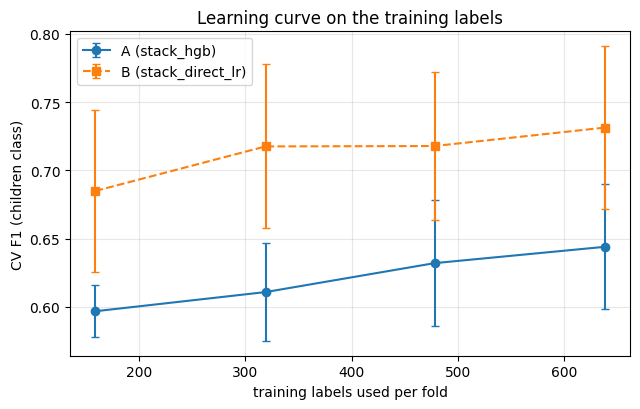

In [8]:
lc = ca.learning_curve(train, sel); lc.round(4).to_csv(OUT / "learning_curve.csv", index=False); display(lc.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for v, g in lc.groupby("variant"):
    ax.errorbar(g.training_labels, g.cv_f1_mean, yerr=g.cv_f1_sd, marker="o" if v == "A" else "s", ls="-" if v == "A" else "--", capsize=3, label=f"{v} ({g.family.iloc[0]})")
ax.set(xlabel="training labels used per fold", ylabel="CV F1 (children class)", title="Learning curve on the training labels"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "children_learning_curve.png", dpi=130); plt.show()

## 7. Fresh test set (evaluated once)
The selected A and B models are refit on all 797 training labels and scored once on the 291 fresh-test books. For context the same books are also scored with the *existing* phase-2 juvenile-marker models used directly as a "children" prediction (the marker also covers teens), and with the always-"not children" baseline.

In [9]:
sel_time = pd.Timestamp((OUT / "cv_selection_written_utc.txt").read_text()); assert sel_time < pd.Timestamp.utcnow(), "selection must exist before the test"
res, probs = ca.evaluate_test(train, test, sel)
y = test.child.to_numpy(); preds = {"A": (probs["A"] > .5).astype(int), "B": (probs["B"] > .5).astype(int), "dummy": np.zeros(len(y), int), **ca.old_juvenile_predictions(test)}
rows = []
for name, pr in preds.items():
    label = {"A": f"NEW A: metadata only ({res['A']['family']})", "B": f"NEW B: metadata + description ({res['B']['family']})", "dummy": "baseline: always 'not children'"}.get(name, name)
    rows.append({"model": label, **ca.prf(y, pr)})
R = pd.DataFrame(rows); R.round(4).to_csv(OUT / "test_results.csv", index=False)
print(f"fresh test: {len(y)} books, {int(y.sum())} children ({y.mean():.1%}); evaluated once"); display(R.round(3))

fresh test: 291 books, 102 children (35.1%); evaluated once


,model,precision,recall,f1,accuracy,tp,fp,fn,tn
0,NEW A: metadata only (stack_hgb),0.627,0.725,0.673,0.753,74,44,28,145
1,NEW B: metadata + description (stack_direct_lr),0.800,0.784,0.792,0.856,80,20,22,169
2,baseline: always 'not children',0.000,0.000,0.000,0.649,0,0,102,189
3,"old juvenile-tag model, classical A",0.523,0.657,0.583,0.670,67,61,35,128
4,"old juvenile-tag model, classical B",0.673,0.667,0.670,0.770,68,33,34,156
5,"old juvenile-tag model, neural A",0.507,0.676,0.580,0.656,69,67,33,122
6,"old juvenile-tag model, neural B",0.646,0.716,0.679,0.763,73,40,29,149


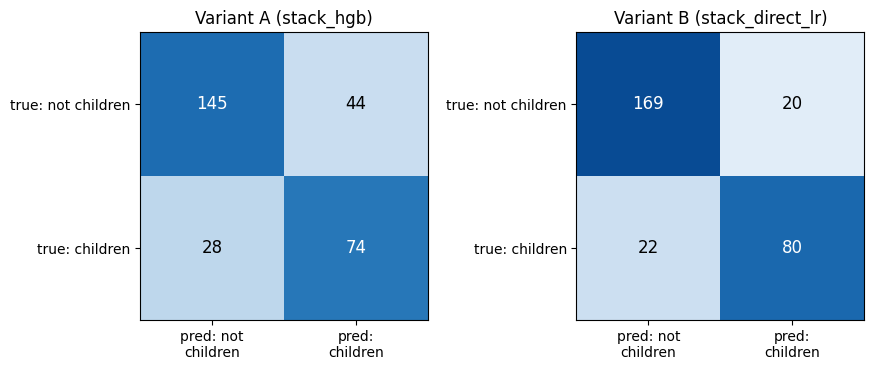

Variant A:


,pred: not children,pred: children
true: not children,145,44
true: children,28,74


Variant B:


,pred: not children,pred: children
true: not children,169,20
true: children,22,80


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8)); cms = {}
for a, v in zip(ax, ["A", "B"]):
    cm = ca.confusion(y, preds[v]); cms[v] = cm; a.imshow(cm.values / cm.values.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2): a.text(j, i, int(cm.values[i, j]), ha="center", va="center", color="black" if cm.values[i, j] / cm.values[i].sum() < .6 else "white", fontsize=12)
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["pred: not\nchildren", "pred:\nchildren"], yticklabels=["true: not children", "true: children"], title=f"Variant {v} ({res[v]['family']})")
plt.tight_layout(); plt.savefig(FIG / "children_confusion_matrices.png", dpi=130); plt.show()
pd.concat({v: cms[v] for v in cms}).to_csv(OUT / "test_confusion.csv")
for v in cms: print(f"Variant {v}:"); display(cms[v])

In [11]:
g = test.ol_group.to_numpy()
pairs = [("description effect (B - A)", "A", "B"), ("A minus baseline", "dummy", "A"), ("B minus baseline", "dummy", "B"),
         ("new A minus old juvenile-tag classical A", "old juvenile-tag model, classical A", "A"), ("new B minus old juvenile-tag classical B", "old juvenile-tag model, classical B", "B"),
         ("new A minus old juvenile-tag neural A", "old juvenile-tag model, neural A", "A"), ("new B minus old juvenile-tag neural B", "old juvenile-tag model, neural B", "B")]
bt = ca.boot_compare(y, g, preds, pairs)
bt = bt.rename(columns=lambda c: c.replace("juv_", "children_"))
keep = ["comparison"] + [f"{m}_{s}" for m in ("children_precision", "children_recall", "children_f1", "accuracy") for s in ("mean", "lo95", "hi95")]
bt[keep].round(4).to_csv(OUT / "test_bootstrap.csv", index=False)
print("Group-level bootstrap (1,000 resamples of work groups), second minus first; intervals that include 0 are not distinguishable from noise"); display(bt[keep].round(3))
pd.DataFrame({"identifier": test.identifier, "provisional_label": test.label, "children_true": y, "prob_children_A": np.round(probs["A"], 4), "prob_children_B": np.round(probs["B"], 4),
              "pred_A": preds["A"], "pred_B": preds["B"]}).to_csv(OUT / "test_predictions.csv", index=False)

Group-level bootstrap (1,000 resamples of work groups), second minus first; intervals that include 0 are not distinguishable from noise


,comparison,children_precision_mean,children_precision_lo95,children_precision_hi95,children_recall_mean,children_recall_lo95,children_recall_hi95,children_f1_mean,children_f1_lo95,children_f1_hi95,accuracy_mean,accuracy_lo95,accuracy_hi95
0,description effect (B - A),0.172,0.092,0.245,0.062,-0.011,0.149,0.121,0.059,0.189,0.103,0.055,0.155
1,A minus baseline,0.628,0.533,0.713,0.726,0.636,0.808,0.672,0.593,0.744,0.103,0.024,0.172
2,B minus baseline,0.800,0.716,0.874,0.787,0.703,0.865,0.793,0.731,0.853,0.207,0.144,0.268
3,new A minus old juvenile-tag classical A,0.105,0.028,0.186,0.069,-0.051,0.188,0.091,0.005,0.177,0.084,0.021,0.148
4,new B minus old juvenile-tag classical B,0.126,0.050,0.204,0.118,0.030,0.204,0.122,0.057,0.190,0.086,0.041,0.131
5,new A minus old juvenile-tag neural A,0.121,0.041,0.202,0.048,-0.061,0.170,0.093,0.013,0.177,0.097,0.031,0.162
6,new B minus old juvenile-tag neural B,0.154,0.079,0.230,0.070,-0.010,0.150,0.114,0.055,0.178,0.093,0.048,0.141


## 8. Where the errors are (fresh test, variant B)

In [12]:
tt = test.assign(pred_B=preds["B"], pred_A=preds["A"], prob_B=probs["B"])
fp = tt[(tt.pred_B == 1) & (tt.child == 0)]; fn = tt[(tt.pred_B == 0) & (tt.child == 1)]
print(f"false positives {len(fp)} by provisional label: {fp.label.value_counts().to_dict()} | false negatives {len(fn)}")
print("median pages: children %.0f, teen %.0f, adult %.0f" % tuple(np.expm1(tt.groupby("label").log_pages.median()[["C", "Y", "A"]])))
cols = ["title_text", "label", "publication_year", "prob_B"]
print("\nlargest false positives (model very sure, label says not children):"); display(fp.sort_values("prob_B", ascending=False)[cols].head(10).round(2))
print("false negatives (children's books the model misses):"); display(fn.sort_values("prob_B")[cols].head(10).round(2))

false positives 20 by provisional label: {'Y': 15, 'A': 5} | false negatives 22
median pages: children 182, teen 328, adult 342

largest false positives (model very sure, label says not children):


,title_text,label,publication_year,prob_B
139,bloodfate,Y,2013,0.97
235,missing since monday,Y,1986,0.97
197,the giant under the snow; a story of suspense,Y,1970,0.89
38,the sweet dead life,Y,2013,0.86
263,two lies and a spy,Y,2013,0.82
168,the source of magic,A,1979,0.82
255,over the edge,Y,1989,0.78
22,tempest,Y,2012,0.77
53,above world,Y,2012,0.77
74,michael vey : the prisoner of cell 25,Y,2011,0.76


false negatives (children's books the model misses):


,title_text,label,publication_year,prob_B
8,magyk,C,2006,0.07
176,mirrorscape,C,2009,0.09
94,"run, bobby, run!",C,2008,0.11
186,rogue knight,C,2014,0.13
16,the call to shakabaz,C,2007,0.18
60,the rise and fall of darth vader,C,2007,0.18
161,the fourteenth summer of angus jack,C,2015,0.21
165,the power of the rellard,C,1989,0.22
185,clash of the sky galleons,C,2007,0.26
5,"20,000 leagues under the sea",C,1994,0.27


## 9. Honest context: the exploratory pilot

In [13]:
pilot = pd.read_csv(OUT / "pilot" / "children_only_pilot_scores.csv")
print("The pilot (saved unchanged in report/ml/children/pilot/) was developed AFTER looking at the 158-book check, so its numbers are exploratory and are not comparable with the fresh-test results above:")
display(pilot.round(3))

The pilot (saved unchanged in report/ml/children/pilot/) was developed AFTER looking at the 158-book check, so its numbers are exploratory and are not comparable with the fresh-test results above:


,model,precision,recall,f1,accuracy,tp,fp,fn
0,"BASELINE existing juvenile-tag model, classical A",0.440,0.537,0.484,0.702,22,28,19
1,"BASELINE existing juvenile-tag model, classical B",0.538,0.512,0.525,0.760,21,18,20
2,"BASELINE existing juvenile-tag model, neural B",0.489,0.561,0.523,0.734,23,24,18
3,"existing tag-model score alone, threshold tuned (A: no description)",0.354,0.561,0.434,0.620,23,42,18
4,"existing tag-model score alone, threshold tuned (B: with description)",0.500,0.415,0.453,0.740,17,17,24
5,stacked: tag score + pages + year (A),0.566,0.732,0.638,0.785,30,23,11
6,stacked: tag score + pages + year (B),0.593,0.780,0.674,0.804,32,22,9


## 10. Findings

All numbers come from this executed notebook. **Fresh test set: 291 books (102 children = 35 %), in work groups disjoint from every training label, evaluated once** after the model choice was saved. Labels are provisional (AI-assigned under written rules, not human-verified).

| Fresh test (target: intended children's audience) | Precision | Recall | F1 | Accuracy | Confusion (TN / FP / FN / TP) |
|---|---|---|---|---|---|
| **New B: metadata + description text** (logistic regression on tag scores + pages/year/title + words) | **0.800** | **0.784** | **0.792** | **85.6 %** | 169 / 20 / 22 / 80 |
| New A: metadata only (small gradient-boosted trees) | 0.627 | 0.726 | 0.673 | 75.3 % | 145 / 44 / 28 / 74 |
| Old juvenile-tag model used directly, classical B | 0.673 | 0.667 | 0.670 | 77.0 % | 156 / 33 / 34 / 68 |
| Old juvenile-tag model used directly, neural B | 0.646 | 0.716 | 0.679 | 76.3 % | 149 / 40 / 29 / 73 |
| Baseline: always "not children" | 0 | 0 | 0 | 65.0 % | 189 / 0 / 102 / 0 |

**Models were chosen by training cross-validation only** (F1 of the children class, 797 labels, grouped folds): CV F1 0.731 for the chosen B model and 0.644 for the chosen A model. The test F1 (0.792 for B) is higher than the CV figure; the fresh test has a larger share of children (35 % against 29 %) and only 102 positives, so do not read this as an improvement.

**Do descriptions help? Yes, mainly by removing false alarms.** B minus A on the same 291 books (group bootstrap, 95 % interval): F1 +0.121 (+0.059 to +0.189), precision +0.172 (+0.092 to +0.246), accuracy +10.3 points (+5.5 to +15.5); recall +0.062, whose interval (−0.011 to +0.149) includes 0, so a recall gain is not established. Within cross-validation B beat A for every model family.

**Is the children-only model better than reusing the juvenile-marker model? Yes on this target.** New B minus old classical B: F1 +0.122 (+0.057 to +0.190), precision +0.126, recall +0.118; against the old neural B: F1 +0.114 (+0.055 to +0.178). This compares a model aimed at the right target with models aimed at the catalogue marker, not like-for-like algorithms.

**Where the errors are.** Of the 20 false alarms of B, 15 are books I labelled teen/young adult and 5 adult (for example Bloodfate, Missing Since Monday, The Sweet Dead Life, Two Lies and a Spy): the children-versus-teen boundary is the main limit. Of the 22 misses, many are middle-grade fantasy/adventure with adult-sounding blurbs (Magyk, Mirrorscape, Rogue Knight, The Call to Shakabaz). Page count is informative (median 182 pages for children's books, 328 for teen, 342 for adult).

**More labels.** Training-CV F1 rose from 0.685 (159 labels) to 0.731 (638 labels) for B and from 0.597 to 0.644 for A, still rising slowly. More labels may help, but this does not guarantee a particular accuracy.

**Limits.**
* **The labels are the weak point.** The same AI labeller produced the training and test labels under one rulebook, so the test cannot reveal a systematic difference from a human's judgement. The 80-book review sheet has not been reviewed yet; until it is, the numbers mean "agreement with provisional labels".
* One locked test of 291 books (102 positives): the intervals above are wide, and the interval ignores the choice of sample.
* The cohort is English archive.org books in three genres (science fiction, fantasy, mystery/thriller) from 1840-2020; results do not carry over to other kinds of books.
* The target is intended audience as judged from title, author and blurb; it does not say a book is suitable for any particular child.
* The pilot (report/ml/children/pilot/) was exploratory, developed after looking at the 158-book check; its numbers are not comparable with the fresh test.

## 11. Reproduce
```bash
pip install -r requirements-analysis.txt
# prerequisite: notebook 06 (creates the phase-2 juvenile split and the saved test predictions); labels and splits are committed
cd notebooks && jupyter nbconvert --to notebook --execute --inplace 08_children_only_audience.ipynb
```
Files: labels `data/labels/children_audience_labels.csv`, rules `docs/CHILDREN_LABEL_RULES.md`, code `notebooks/children_audience.py`, results `report/ml/children/` (splits with hashes, CV/test/bootstrap tables, learning curve, figures, review sheet, `pilot/`). Seeds: split 2026, sampling 2027/2028/2029/2030.